# 10 — Bolsões de desempenho e o top 1%

**Objetivo:** buscar variações como a de "vídeos acima de 480 s" e tratá-las como **insights exploratórios**, ranqueados pelo nível de evidência.
Depois, olhar os posts **top 1%** e procurar o que eles têm em comum **antes** da postagem.

**Bolsão** = um valor de atributo (ex.: categoria = tech), uma janela de variável numérica (ex.: duração entre 480 e 599) ou uma combinação de dois valores (ex.: TikTok · tech).
**Métrica** = % dos posts do bolsão que chegam ao top 5% de views, likes ou comentários (base: 5%).

| Evidência | Critério | Como usar |
|---|---|---|
| **robusta** | sobrevive à correção para todos os testes (FDR) | decisão |
| **replicada** | p < 0,05 na 1ª metade do período **e** mesma direção com p < 0,05 na 2ª metade | hipótese forte: priorizar teste A/B |
| **exploratória** | p < 0,05 nos dados completos | hipótese: monitorar |

Referência de acaso: ~5% dos bolsões dão p < 0,05, e ~5% das descobertas da 1ª metade replicam por acaso.

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

from scipy import stats
from statsmodels.stats.multitest import multipletests
from social_insights import discovery as dv
METRICS = ["views", "likes", "comments_count"]
TABLES = {m: dv.scan_pockets(df, m) for m in METRICS}
summary = pd.DataFrame({m: dv.replication_summary(t) for m, t in TABLES.items()}).T
summary

52,214 posts


,bolsões testados,"p<0,05 nos dados completos",esperado por acaso,descobertos na 1ª metade,replicaram na 2ª metade,taxa de replicação (%),replicação esperada por acaso (%),p (replicação acima do acaso),robustos (FDR)
views,1569.0000,84.0000,78.0000,94.0000,6.0000,6.3830,5.0000,0.3302,0.0000
likes,1569.0000,62.0000,78.0000,84.0000,5.0000,5.9524,5.0000,0.4111,0.0000
comments_count,1569.0000,91.0000,78.0000,64.0000,2.0000,3.1250,5.0000,0.8361,0.0000


## 1. Mapa de bolsões (vulcão)

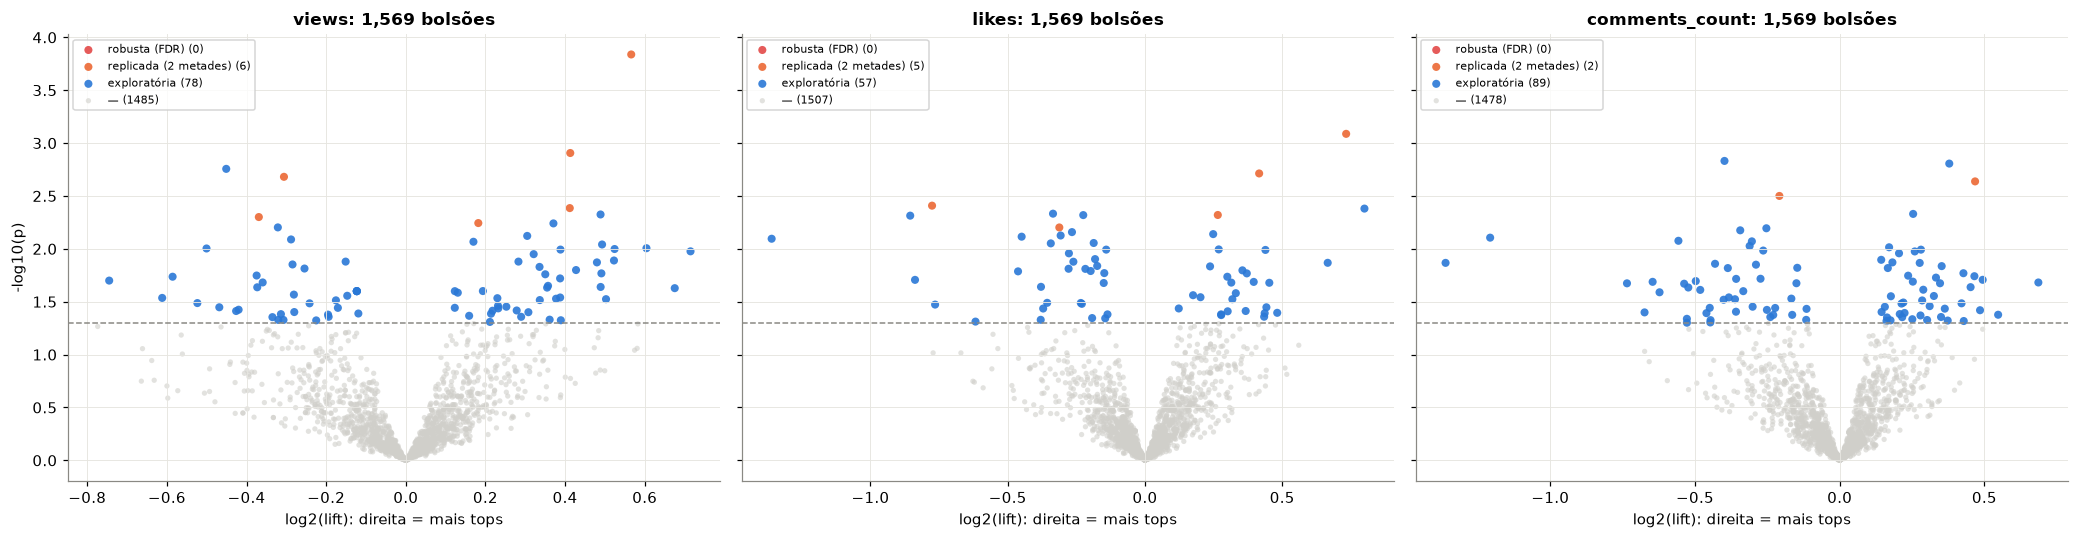

In [2]:
COLORS = {"robusta (FDR)": "#e34948", "replicada (2 metades)": plots.ORANGE, "exploratória": plots.BLUE, "—": "#d0cfca"}
fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharey=True)
for ax, m in zip(axes, METRICS):
    t = TABLES[m]
    for tier, color in COLORS.items():
        s = t[t["evidência"] == tier]
        ax.scatter(np.log2(s["lift"]), -np.log10(s["p_value"]), s=12 if tier == "—" else 28, color=color, label=f"{tier} ({len(s)})",
                   alpha=0.6 if tier == "—" else 0.9, edgecolors="none")
    ax.axhline(-np.log10(0.05), color=plots.GRAY, linestyle="--", linewidth=1)
    ax.set_xlabel("log2(lift): direita = mais tops"); ax.set_title(f"{m}: {len(t):,} bolsões"); ax.legend(fontsize=7, loc="upper left")
axes[0].set_ylabel("-log10(p)")
fig.tight_layout(); plt.show()

## 2. Os padrões se repetem no tempo?

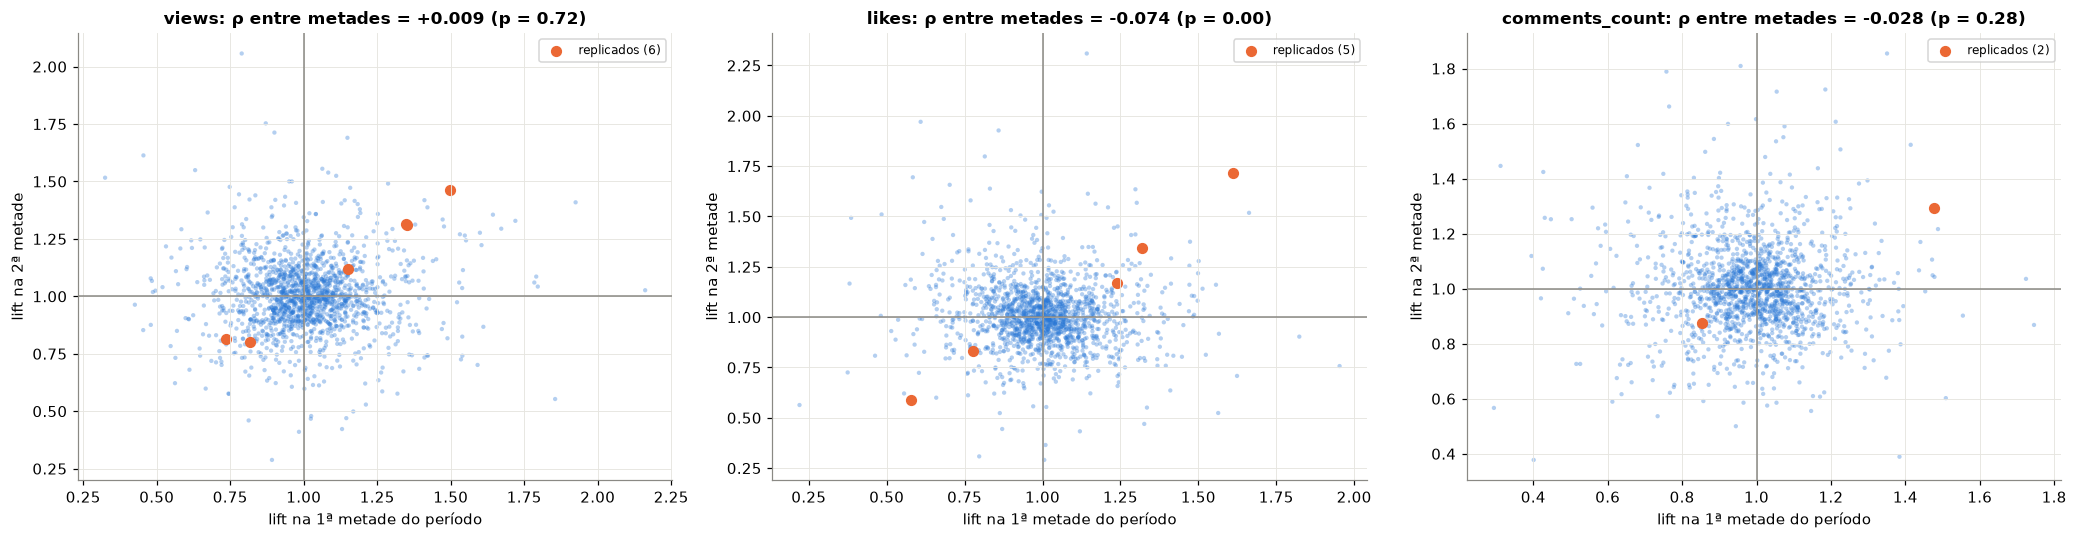

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, m in zip(axes, METRICS):
    t = TABLES[m].dropna(subset=["lift 1ª metade", "lift 2ª metade"])
    rho, p = stats.spearmanr(t["lift 1ª metade"], t["lift 2ª metade"])
    ax.scatter(t["lift 1ª metade"], t["lift 2ª metade"], s=8, alpha=0.35, color=plots.BLUE, edgecolors="none")
    rep = t[t["replicou"]]
    ax.scatter(rep["lift 1ª metade"], rep["lift 2ª metade"], s=40, color=plots.ORANGE, label=f"replicados ({len(rep)})")
    ax.axhline(1, color=plots.GRAY, linewidth=1); ax.axvline(1, color=plots.GRAY, linewidth=1)
    ax.set_xlabel("lift na 1ª metade do período"); ax.set_ylabel("lift na 2ª metade")
    ax.set_title(f"{m}: ρ entre metades = {rho:+.3f} (p = {p:.2f})"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

**Como ler:** se os bolsões tivessem efeito real, os pontos formariam uma diagonal (quem é bom na 1ª metade continua bom na 2ª).
Uma nuvem redonda (ρ ≈ 0) indica que, **no conjunto**, os padrões não persistem. Os pontos laranja são os que persistiram, e eles são os candidatos mais fortes.
O p do ρ superestima a evidência, porque os bolsões se sobrepõem (os mesmos posts entram em muitos deles). Por isso o ρ = −0,07 de likes **não** indica efeito invertido, só ausência de persistência no conjunto.

## 3. Insights exploratórios (ranqueados)

In [4]:
for m in METRICS:
    display(Markdown(f"### {m}"))
    display(dv.insight_cards(TABLES[m], n=8).style.hide(axis="index").set_properties(**{"text-align": "left"}))

### views

evidência,insight,como validar
replicada (2 metades),"length_bin × audience_gender_distribution = longo (180–360) · unknown: 7.4% dos 1,228 posts chegam ao top 5% de views (1.48x, mais que o resto). 1ª metade 1.50x · 2ª metade 1.46x · q = 0.23",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"daypart × weekday = madrugada · Thursday: 6.7% dos 1,892 posts chegam ao top 5% de views (1.33x, mais que o resto). 1ª metade 1.35x · 2ª metade 1.31x · q = 0.82",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_category × length_bin = beauty · muito longo (360+): 4.2% dos 5,199 posts chegam ao top 5% de views (0.81x, menos que o resto). 1ª metade 0.82x · 2ª metade 0.80x · q = 0.82",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_category × weekday = tech · Friday: 6.7% dos 1,484 posts chegam ao top 5% de views (1.33x, mais que o resto). 1ª metade 1.35x · 2ª metade 1.31x · q = 0.86",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_category × weekday = lifestyle · Friday: 4.0% dos 2,997 posts chegam ao top 5% de views (0.77x, menos que o resto). 1ª metade 0.74x · 2ª metade 0.81x · q = 0.86",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"follower_count (janela) = 599,598–799,657: 5.6% dos 10,443 posts chegam ao top 5% de views (1.13x, mais que o resto). 1ª metade 1.15x · 2ª metade 1.12x · q = 0.86",teste A/B ou acompanhamento nos próximos posts
exploratória,"audience_gender_distribution × audience_location = male · Germany: 3.8% dos 2,611 posts chegam ao top 5% de views (0.73x, menos que o resto). 1ª metade 0.81x · 2ª metade 0.66x · q = 0.82",teste A/B ou acompanhamento nos próximos posts
exploratória,"weekday × audience_location = Thursday · India: 7.1% dos 950 posts chegam ao top 5% de views (1.40x, mais que o resto). 1ª metade 1.60x · 2ª metade 1.22x · q = 0.86",teste A/B ou acompanhamento nos próximos posts


### likes

evidência,insight,como validar
replicada (2 metades),"content_type × language = text · Japanese: 8.3% dos 494 posts chegam ao top 5% de likes (1.66x, mais que o resto). 1ª metade 1.61x · 2ª metade 1.72x · q = 0.84",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"length_bin × weekday = longo (180–360) · Wednesday: 6.6% dos 1,719 posts chegam ao top 5% de likes (1.33x, mais que o resto). 1ª metade 1.32x · 2ª metade 1.34x · q = 0.84",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"weekday × audience_location = Monday · USA: 3.0% dos 913 posts chegam ao top 5% de likes (0.58x, menos que o resto). 1ª metade 0.58x · 2ª metade 0.59x · q = 0.84",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_category × language = lifestyle · Chinese: 5.9% dos 4,138 posts chegam ao top 5% de likes (1.20x, mais que o resto). 1ª metade 1.24x · 2ª metade 1.17x · q = 0.84",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"content_category × length_bin = tech · médio (60–180): 4.1% dos 3,919 posts chegam ao top 5% de likes (0.81x, menos que o resto). 1ª metade 0.78x · 2ª metade 0.83x · q = 0.84",teste A/B ou acompanhamento nos próximos posts
exploratória,"follower_tier × audience_location = micro (10–50K) · USA: 8.7% dos 287 posts chegam ao top 5% de likes (1.74x, mais que o resto). 1ª metade 1.14x · 2ª metade 2.31x · q = 0.84",teste A/B ou acompanhamento nos próximos posts
exploratória,"follower_tier × weekday = mega (500K+) · Monday: 4.0% dos 3,685 posts chegam ao top 5% de likes (0.79x, menos que o resto). 1ª metade 0.90x · 2ª metade 0.69x · q = 0.84",teste A/B ou acompanhamento nos próximos posts
exploratória,"caption_words (janela) = 6–12: 4.4% dos 8,182 posts chegam ao top 5% de likes (0.86x, menos que o resto). 1ª metade 0.78x · 2ª metade 0.94x · q = 0.84",teste A/B ou acompanhamento nos próximos posts


### comments_count

evidência,insight,como validar
replicada (2 metades),"platform × language = Bilibili · Hindi: 7.9% dos 1,080 posts chegam ao top 5% de comentários (1.38x, mais que o resto). 1ª metade 1.48x · 2ª metade 1.29x · q = 0.82",teste A/B ou acompanhamento nos próximos posts
replicada (2 metades),"caption_words (janela) = 10–14: 5.1% dos 9,146 posts chegam ao top 5% de comentários (0.87x, menos que o resto). 1ª metade 0.85x · 2ª metade 0.88x · q = 0.82",teste A/B ou acompanhamento nos próximos posts
exploratória,"weekday × audience_gender_distribution = Thursday · female: 4.4% dos 2,946 posts chegam ao top 5% de comentários (0.76x, menos que o resto). 1ª metade 0.83x · 2ª metade 0.69x · q = 0.82",teste A/B ou acompanhamento nos próximos posts
exploratória,"daypart × audience_age_distribution = madrugada · 36-50: 7.4% dos 1,939 posts chegam ao top 5% de comentários (1.30x, mais que o resto). 1ª metade 1.44x · 2ª metade 1.17x · q = 0.82",teste A/B ou acompanhamento nos próximos posts
exploratória,"daypart × audience_age_distribution = madrugada · 26-35: 6.7% dos 3,961 posts chegam ao top 5% de comentários (1.19x, mais que o resto). 1ª metade 1.14x · 2ª metade 1.25x · q = 0.82",teste A/B ou acompanhamento nos próximos posts
exploratória,"caption_words (janela) = 12–14: 4.9% dos 5,053 posts chegam ao top 5% de comentários (0.84x, menos que o resto). 1ª metade 0.74x · 2ª metade 0.93x · q = 0.82",teste A/B ou acompanhamento nos próximos posts
exploratória,"length_bin × weekday = médio (60–180) · Wednesday: 4.6% dos 2,778 posts chegam ao top 5% de comentários (0.79x, menos que o resto). 1ª metade 0.81x · 2ª metade 0.76x · q = 0.82",teste A/B ou acompanhamento nos próximos posts
exploratória,"weekday × audience_age_distribution = Wednesday · 50+: 2.5% dos 361 posts chegam ao top 5% de comentários (0.43x, menos que o resto). 1ª metade 0.29x · 2ª metade 0.57x · q = 0.82",teste A/B ou acompanhamento nos próximos posts


## 4. O caso "vídeos acima de 480 s" dentro desta busca
Mesma busca restrita a vídeos (como na análise original): janelas de duração × top 5% de views.
Resultado: **504–599 s** tem lift 0,82 (p = 0,03), ou seja, **evidência exploratória**. Na 2ª metade, p = 0,05; na 1ª, p = 0,24, então não chegou a replicar. Segue como hipótese a monitorar.

In [5]:
videos = df[df.content_type == "video"]
vt = dv.scan_pockets(videos, "views")
windows = vt[vt["dimensão"] == "content_length (janela)"].sort_values("lift")
windows[["bolsão", "posts", "taxa top 5% (%)", "lift", "lift 1ª metade", "lift 2ª metade", "p_value", "q_value", "evidência"]].round(3)

,bolsão,posts,taxa top 5% (%),lift,lift 1ª metade,lift 2ª metade,p_value,q_value,evidência
1344,504–599,3152,4.2200,0.8230,0.8660,0.7840,0.0270,0.8310,exploratória
136,407–599,6318,4.6690,0.9110,0.9270,0.8960,0.1370,0.9150,—
484,10–111,9429,4.8790,0.9560,0.9210,0.9910,0.4070,0.9640,—
759,10–47,3081,4.8360,0.9560,0.8960,1.0140,0.5950,0.9830,—
819,79–111,3185,4.8670,0.9630,0.9650,0.9630,0.6470,0.9900,—
693,10–79,6244,4.8850,0.9630,0.9150,1.0090,0.5440,0.9730,—
733,47–111,6348,4.8990,0.9660,0.9530,0.9800,0.5800,0.9800,—
744,47–142,9468,4.9320,0.9710,0.9530,0.9880,0.5850,0.9800,—
856,79–142,6305,4.9330,0.9750,0.9660,0.9830,0.6780,0.9900,—
999,47–79,3163,4.9320,0.9770,0.9510,1.0010,0.7800,0.9900,—


## 5. Top 1%: o que os melhores posts têm em comum antes de postar?

Top 1%: **528** posts por métrica (views ≥ 10,335 · likes ≥ 1,602 · comentários ≥ 233)

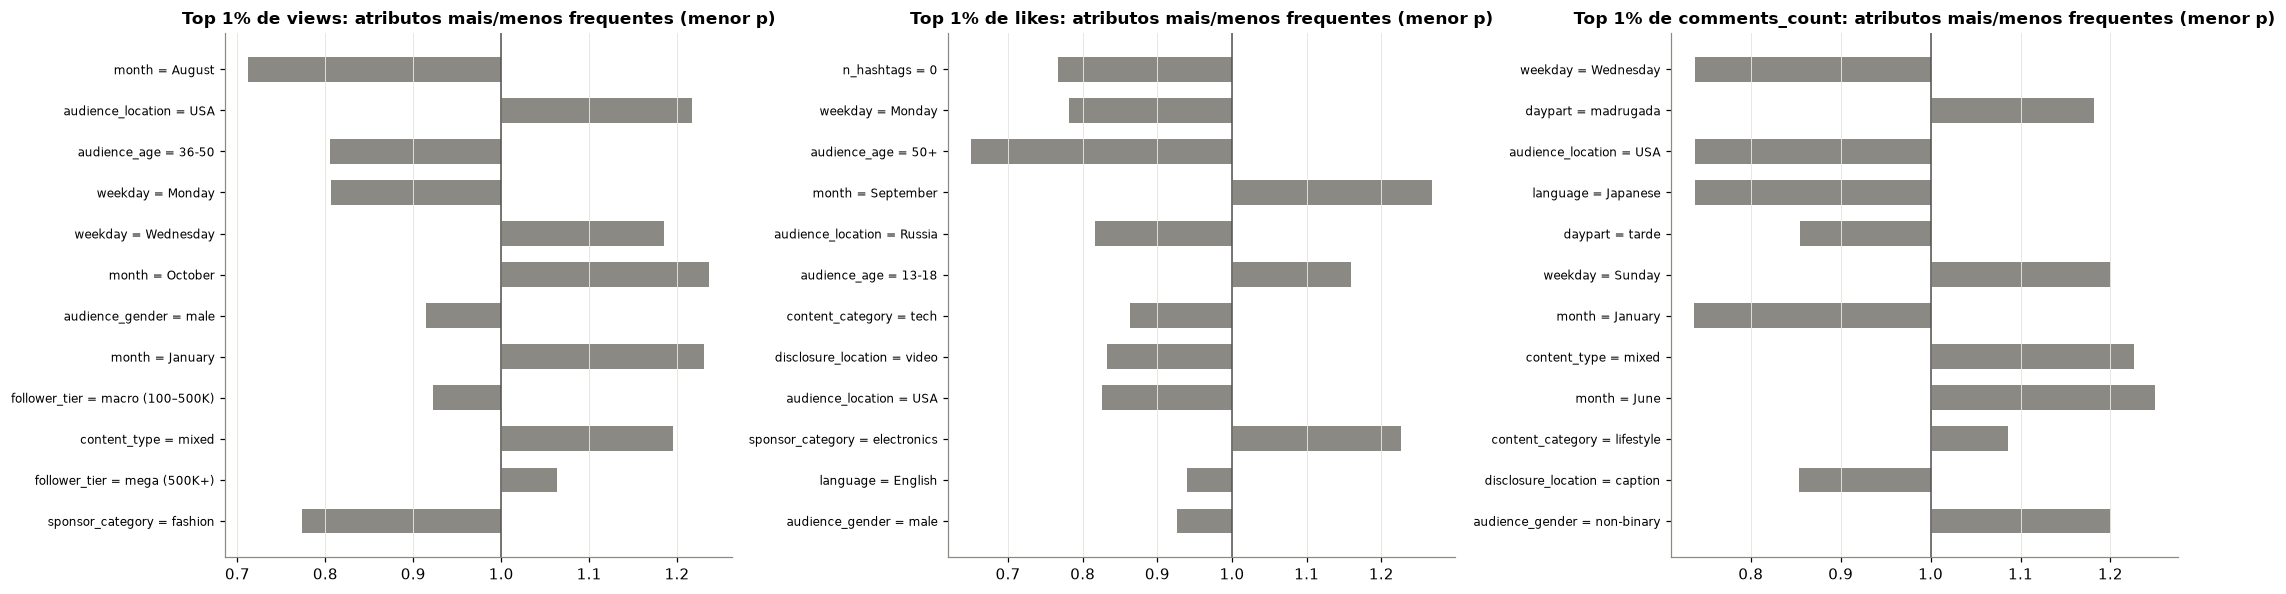

mediana top 1%  mediana demais  \
               variável                                         
views          content_length        177.0000        174.0000   
               follower_count     519076.0000     498271.5000   
               hour                   12.0000         11.0000   
               caption_words          19.0000         18.0000   
likes          content_length        175.0000        174.0000   
               follower_count     505475.0000     498467.0000   
               hour                   11.0000         12.0000   
               caption_words          19.0000         18.0000   
comments_count content_length        166.5000        174.0000   
               follower_count     481145.0000     498745.0000   
               hour                   10.0000         12.0000   
               caption_words          19.0000         18.0000   

                               efeito (rank-biserial)  p_value  p 1ª metade  \
               variável                                                       
views          content_length                  0.0100   0.6810       0.9700   
               follower_count                  0.0200   0.4300       0.7590   
               hour                           -0.0030   0.9100       0.7420   
               caption_words                   0.0110   0.6680       0.2170   
likes          content_length                 -0.0050   0.8540       0.7160   
               follower_count                 -0.0240   0.3300       0.5720   
               hour                           -0.0280   0.2610       0.1900   
               caption_words                   0.0530   0.0320       0.0680   
comments_count content_length                 -0.0290   0.2280       0.0500   
               follower_count                 -0.0220   0.3530       0.3090   
               hour                           -0.0750   0.0020       0.0130   
               caption_words                   0.0400   0.0960       0.2140   

                               p 2ª metade  q_value  q_value (12 testes)  
               variável                                                   
views          content_length       0.5360   0.9080               0.8170  
               follower_count       0.1570   0.9080               0.6460  
               hour                 0.6250   0.9100               0.9100  
               caption_words        0.5340   0.9080               0.8170  
likes          content_length       0.9090   0.8540               0.9100  
               follower_count       0.4100   0.4400               0.6050  
               hour                 0.7820   0.4400               0.6050  
               caption_words        0.2320   0.1300               0.1950  
comments_count content_length       0.8130   0.3040               0.6050  
               follower_count       0.7680   0.3530               0.6050  
               hour                 0.0470   0.0060               0.0190  
               caption_words        0.2630   0.1910               0.3830

In [6]:
TOPS = {m: dv.top_mask(df, m) for m in METRICS}
display(Markdown(f"Top 1%: **{TOPS['views'].sum()}** posts por métrica (views ≥ {df.views.quantile(0.99):,.0f} · "
                 f"likes ≥ {df.likes.quantile(0.99):,.0f} · comentários ≥ {df.comments_count.quantile(0.99):,.0f})"))
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, m in zip(axes, METRICS):
    prof = dv.top_profile(df, m).head(12).iloc[::-1]
    labels = prof["atributo"].str.replace("_distribution", "") + " = " + prof["valor"]
    ax.barh(labels, prof["lift"] - 1, left=1, color=[plots.BLUE if q < 0.05 else plots.GRAY for q in prof["q_value"]], height=0.6)
    ax.axvline(1, color=plots.INK, linewidth=1); ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
    ax.set_title(f"Top 1% de {m}: atributos mais/menos frequentes (menor p)")
fig.tight_layout(); plt.show()
numeric = pd.concat({m: dv.top_numeric_profile(df, m) for m in METRICS})
numeric["q_value (12 testes)"] = multipletests(numeric["p_value"], method="fdr_bh")[1]
numeric.round(3)

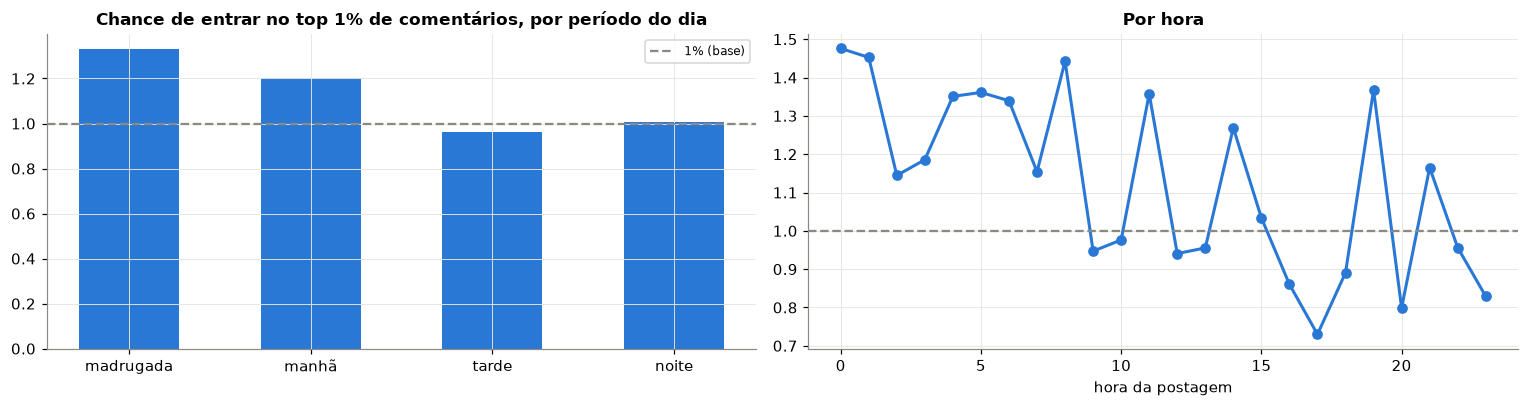

,posts,top,% no top 1% de comentários
daypart,,,
madrugada,13154,175,1.3300
manhã,12953,156,1.2000
tarde,12980,125,0.9600
noite,13127,132,1.0100


In [7]:
p99 = df.comments_count.quantile(0.99)
rate = df.groupby("daypart", observed=True)["comments_count"].agg(posts="size", top=lambda s: int((s >= p99).sum()))
rate["% no top 1% de comentários"] = rate["top"] / rate["posts"] * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].bar(rate.index.astype(str), rate["% no top 1% de comentários"], color=plots.BLUE, width=0.55)
axes[0].axhline(1, color=plots.GRAY, linestyle="--", label="1% (base)"); axes[0].legend(fontsize=8)
axes[0].set_title("Chance de entrar no top 1% de comentários, por período do dia")
hours = df.groupby("hour")["comments_count"].apply(lambda s: (s >= p99).mean() * 100)
axes[1].plot(hours.index, hours.values, "o-", color=plots.BLUE, linewidth=2)
axes[1].axhline(1, color=plots.GRAY, linestyle="--"); axes[1].set_xlabel("hora da postagem"); axes[1].set_title("Por hora")
fig.tight_layout(); plt.show()
rate.round(2)

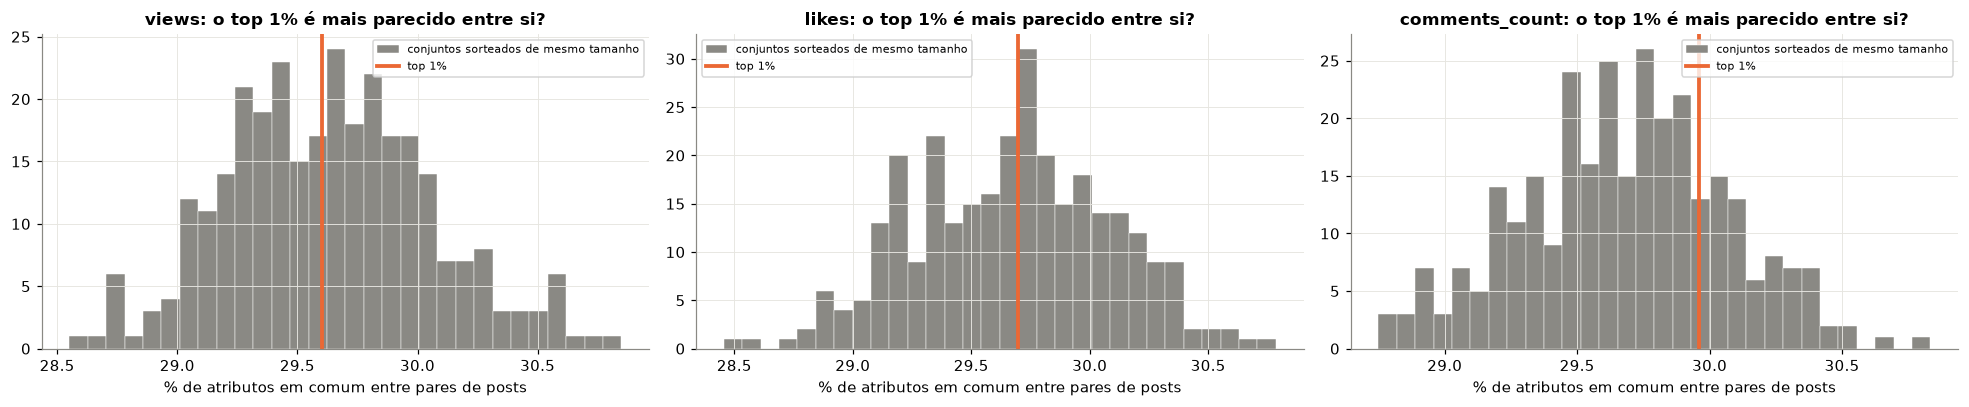

,similaridade no top (%),similaridade em sorteios (%),p similaridade,creators com ≥2 posts no top,esperado por acaso,p creators
métrica,,,,,,
views,29.6040,29.6310,0.5250,28,23.9100,0.2290
likes,29.6980,29.6720,0.5020,17,25.2700,0.9870
comments_count,29.9600,29.6760,0.2390,32,29.2030,0.3060


**O top 1% de uma métrica coincide com o de outra?**

,posts top nas duas,esperado se independentes,p_value
par,,,
views & likes,2,5.5110,0.1940
views & comments_count,5,5.9460,1.0000
views & shares,6,5.8550,0.8360
likes & comments_count,7,6.1370,0.6830
likes & shares,3,6.0430,0.3050
comments_count & shares,10,6.5200,0.1670


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
rows = []
for ax, m in zip(axes, METRICS):
    sim = dv.similarity_test(df, TOPS[m])
    ax.hist(sim["null"], bins=30, color=plots.GRAY, edgecolor="white", linewidth=0.3, label="conjuntos sorteados de mesmo tamanho")
    ax.axvline(sim["similaridade média no top (%)"], color=plots.ORANGE, linewidth=2.5, label="top 1%")
    ax.set_xlabel("% de atributos em comum entre pares de posts"); ax.set_title(f"{m}: o top 1% é mais parecido entre si?"); ax.legend(fontsize=7)
    conc = dv.creator_concentration(df, TOPS[m])
    rows.append({"métrica": m, "similaridade no top (%)": sim["similaridade média no top (%)"], "similaridade em sorteios (%)": sim["similaridade em sorteios (%)"],
                 "p similaridade": sim["p_value"], **{f"{k}": v for k, v in conc.items() if k != "p_value"}, "p creators": conc["p_value"]})
fig.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("métrica").round(3))
display(Markdown("**O top 1% de uma métrica coincide com o de outra?**"))
dv.top_overlap(df, ["views", "likes", "comments_count", "shares"]).round(3)

**Leitura (top 1%):**
- **⭐ Insight mais forte desta busca: horário × comentários.** Os posts do **top 1% de comentários** saem mais cedo (hora mediana **10h** vs. 12h no resto). O efeito sobrevive à correção entre os 12 testes numéricos (q ≈ 0,02) e **se repete nas duas metades do período** (p = 0,013 e 0,047). Pela taxa: **madrugada 1,33%** e **manhã 1,20%** chegam ao top 1% de comentários, contra **tarde 0,96%** e noite 1,01%. É coerente com o bolsão exploratório "hora 0–4 → mais top 5% de comentários". **Hipótese prioritária para teste A/B:** postar conteúdo que busca conversa antes do meio-dia.
- **Perfil (categóricos):** nenhum atributo é significativamente mais frequente no top 1% após a correção. As maiores diferenças são pistas fracas (ex.: no top 1% de views, audiência dos EUA aparece 1,2x mais e posts de agosto, 0,7x). No top 1% de likes, as legendas são ligeiramente mais longas (19 vs. 18 palavras; p = 0,03, q = 0,2), o que é uma pista fraca.
- **Semelhança:** os posts do top 1% compartilham ~29,6% dos atributos entre si, **o mesmo** que conjuntos sorteados. Não existe uma "receita" comum.
- **Creators:** o nº de creators com 2+ posts no top é o esperado por acaso. Não há creators "campeões".
- **Entre métricas:** quase nenhum post é top 1% em duas métricas ao mesmo tempo (o mesmo que o acaso), então "top em views" não é "top em likes".

## 6. Como usar estes insights
1. **Prioridade 1:** horário × comentários (top 1% concentrado de madrugada e de manhã; replicado e com correção).
2. **Os replicados** (laranja) são as próximas apostas para **teste A/B**. Ex.: vídeos longos (180–360 s) com audiência de gênero não identificado (1,48x mais top 5% de views), ou tech às sextas (1,33x).
3. **Os exploratórios** entram em monitoramento: rodar `dv.scan_pockets` a cada mês e ver se o bolsão continua aparecendo.
4. **Cautela:** no conjunto, a taxa de replicação é próxima do acaso (~5%). Por isso cada bolsão é uma **hipótese**, e o teste A/B é o que transforma hipótese em decisão.